<img src="../workshops/img/swdb_logo.jpg" width="900" style="display: block; margin: 0 auto;">

<h1 align="center">Connectomics Exercise 2: Which interneurons target which compartments?</h1>
<h2 align="center">SOLUTIONS</h2>
<h3 align="center">Summer Workshop on the Dynamic Brain 2026</h3>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>A pyramidal cell is not inhibited uniformly. Different inhibitory subclasses place their synapses in different places on it, and that arrangement is a large part of what those subclasses <i>are</i>. We build that  <b>L5-ET</b> cells — thick-tufted, subcortically projecting, with some of the most elaborate dendrites in cortex.
<p>We will build also everything directly from CAVE to get used to working with direct data access.
<p>Disclaimer: Claude was used to help generate exercise details and solutions.

</div>

In [1]:
import sys
from os.path import join as pjoin

mat_version = 1196
sys.path.append(pjoin("..", "utils"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import ossify as osy
from caveclient import CAVEclient
from standard_transform.datasets import v1dd_ds

from utils import cell_type_palette

sns.set_context("notebook")
plt.rcParams["figure.dpi"] = 110

/opt/conda/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.2) or chardet (7.6.0)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>If you have not set up a CAVE token yet, uncomment the <code>setup_token</code> line, run it once, and follow the instructions.

</div>

In [4]:
# CAVEclient.setup_token("https://global.em.brain.allentech.org")
client = CAVEclient(datastack_name="v1dd_public", version=mat_version)

<div style="border-left: 3px solid #B8860B; padding: 1px; padding-left: 10px; background: #FFF8DC; ">

<p><b>If a CAVE query takes longer than three minutes, stop it.</b>
<p>The CAVE queries in this notebook should return in seconds. Past about three minutes it is not going to finish on its own — interrupt the kernel (the ■ button, or <i>Kernel → Interrupt</i>) and run the cell again.
<p>If the same cell hangs a second time, flag a TA rather than waiting it out. It usually means the server is under load or the request is larger than it looks, and both are worth someone checking.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h3> The CAVE calls you will need </h3>
<p>Every query in this notebook is one of four shapes. The point of the exercises is the analysis, not remembering the API, so here they all are.
<p><b>Discover what exists.</b>
<pre><code>
client.materialize.get_tables()          # queryable tables
client.materialize.get_views()           # views (pre-joined convenience tables)
client.materialize.get_versions()        # materialization versions
</code></pre>
<p><b>Pull a whole table.</b> The <code>tables.&lt;name&gt;()</code> accessor takes filters as keyword arguments; <code>.get_all()</code> skips the filter and returns everything.
<pre><code>
df = client.materialize.tables.cell_type_multifeature_v1().get_all(
    split_positions=True,          # pt_position -> pt_position_x / _y / _z
    desired_resolution=[1, 1, 1],  # positions in NANOMETRES rather than voxels
)

df = client.materialize.tables.proofreading_status_and_strategy(
    status_axon=True,              # any column can be a filter kwarg
).query(split_positions=True)
</code></pre>
<p><b>Query synapses.</b> <code>pre_ids</code> and <code>post_ids</code> each take a list of root ids. Giving both is a logical AND — only synapses from those cells onto those cells — which is how you ask a narrow question cheaply instead of filtering a huge answer afterwards.
<pre><code>
syn = client.materialize.synapse_query(
    post_ids=some_root_ids,                  # or pre_ids=..., or both
    desired_resolution=[1, 1, 1],
    split_positions=True,
)
</code></pre>
<p><b>Query a table by an explicit list of ids.</b> Needed for reference tables such as the synapse compartment predictions, which are keyed to synapse ids rather than to cells.
<pre><code>
client.materialize.query_table(
    "synapse_target_predictions_ssa",
    filter_in_dict={"target_id": [int(i) for i in some_synapse_ids]},
    select_columns=["target_id", "tag"],
    merge_reference=False,   # return the reference table's own rows, unjoined
    log_warning=False,
)
</code></pre>
<p>Two things that will bite you regardless of which shape you use:
<ul>
<li><b>Root ids come back as a nullable <code>Int64</code></b>, which is not JSON-serialisable. Passing <code>df.pt_root_id.values</code> into a query raises <code>TypeError: Object of type IntegerArray is not JSON serializable</code>. Use <code>root_ids()</code> below.
<li><b>A query that is too large returns <code>502 Bad Gateway</code></b>, not a helpful error. The limit is on the size of the response, not the number of ids. Question 4 makes you meet this properly.
</ul>

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h3> Pre-screened cells </h3>
<p>These were chosen ahead of time — soma away from the volume edge, an apical reaching L1, all four inhibitory subclasses present among its proofread inputs, and no merge balloon in the radius profile. Being handed a curated example is normal practice and rarely admitted to; the last exercise asks you to pick your own and see what goes wrong.
<p><b>These ids belong to materialization 1196.</b> If the dataset is rematerialized they must be regenerated.

</div>

In [5]:
EXEMPLAR_L5ET = 864691132734343191
BACKUP_L5ET = [864691132830244868, 864691132669405014]

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>The helper the note above refers to:

</div>

In [6]:
def root_ids(series):
    """Root ids as a plain uint64 array, safe to hand to a CAVE query."""
    return series.dropna().astype("uint64").to_numpy()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Coordinates come in three flavours and mixing them fails silently.</b> Voxels, raw nanometres, and <i>transformed</i> microns (rotated so the pia is flat, with y as cortical depth). The last is the most meaningful for geometry — and subtracting a raw-µm position from a transformed-µm one adds a large fixed offset with no error and no warning. Push every transform through one helper so it cannot happen:

</div>

In [7]:
def to_transformed_um(df, prefix):
    """Columns f'{prefix}_x/y/z' in nanometres -> transformed microns, pia-flat."""
    cols = [f"{prefix}_{ax}" for ax in "xyz"]
    return v1dd_ds.transform("nm").apply(df[cols].values)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>A synapse's position relative to the cell it lands on.</b> Question 3 will ask you to compute the location of a synapse relative to the cell body in spherical coordinates. Feel free to write your own function, but rather than get hung up on geometry you can also use this function to accomplish that. Given a set of points and a soma, both in transformed µm, it returns how far each point is from that soma and in what direction — with the compass flattened to a single angle.

</div>

In [8]:
def r_theta(points_um, soma_um):
    """Spherical-ish coordinates about a soma, with azimuth dropped.

    r     : straight-line distance from the soma, µm
    theta : degrees out of the tangential plane; +90 = straight toward the pia,
            0 = level with the soma, -90 = straight down.

    Dropping azimuth assumes the target is roughly rotationally symmetric about the
    pia axis -- fair for a pyramidal cell, wrong for anything with a planar arbor.
    """
    delta = points_um - soma_um
    lateral = np.hypot(delta[:, 0], delta[:, 2])
    return (
        np.linalg.norm(delta, axis=1),
        np.degrees(np.arctan2(-delta[:, 1], lateral)),
    )

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Plotting that frame.</b> <code>cloud</code> draws one panel of synapses in a target's own frame. It is here so the figures later stay short; read it when you first use it in Question 4.

</div>

In [9]:
def cloud(ax, df, title, color):
    """Every synapse in the frame of the cell it landed on. Azimuth was collapsed, so
    lateral distance is a magnitude -- mirror it, which is what the rotational-symmetry
    assumption already claims."""
    lat = df.r_um * np.cos(np.radians(df.theta_deg))
    vert = df.r_um * np.sin(np.radians(df.theta_deg))
    ax.scatter(
        np.r_[lat, -lat], np.r_[vert, vert], s=3.0, alpha=0.18, lw=0, color=color
    )
    ax.scatter([0], [0], marker="*", s=180, c="k", zorder=6)
    for rad in (25, 50, 100, 150):
        ax.add_artist(plt.Circle((0, 0), rad, fill=False, color="0.6", lw=0.7, ls=":"))
    ax.set(
        xlim=(-160, 160),
        ylim=(-160, 200),
        aspect="equal",
        title=title,
        xlabel="lateral distance (µm)",
    )
    # The frame is clipped so the tight cloud is readable; say how much falls outside
    # rather than letting the crop quietly imply the cloud ends there.
    out = 100 * (df.r_um > 160).mean()
    if out > 1:
        ax.text(
            0.97,
            0.03,
            f"{out:.0f}% beyond frame",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=8,
            color="0.4",
        )

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<hr>
<h2> Question 1 — Who are the L5-ET cells, and whose reconstruction do you have to trust? </h2>
<p><b>ET</b> is <i>extratelencephalic</i>: They are a kind of pyramidal cell that projects out of cortex, to thalamus, superior colliculus and brainstem. They are also known as thick-tufted cells, with a long apical trunk rising to a (sometimes very wide) tuft in Layer 1, plus a basal skirt around the soma.
<p>Inhibitory cells come pre-sorted into four subclasses — <code>PTC</code>, <code>DTC</code>, <code>ITC</code>, <code>STC</code> — by <code>cell_type_multifeature_v1</code>, a classifier built on <b>soma, nucleus, dendrite and spine morphology</b>. Note what is <i>not</i> in that list: the classifier never sees where a cell's synapses land.
<p><b>Treat the four labels as opaque for now.</b> They are four groups that look different down a microscope, nothing more. Whether they also <i>behave</i> differently — whether they put their synapses in different places on a target — is the question this module aims to answer. The names do stand for something, and we come back to them at the end; unpacking them now would hand you the answer before you have measured anything.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 1:</b> Build a table of all classified cells from <code>cell_type_multifeature_v1</code> and remove any duplicate root ids that do not have a well-defined type. How many of each type, and which are excitatory vs inhibitory?
<p>Note: The table query function is <code>client.materialize.query_table</code>, or you can also use <code>client.materialize.tables.&lt;table&gt;.query</code>
<p><i>Solution note: Later cells expect this table to be called <code>cell_df</code>.</i>

</div>

In [10]:
cell_df = client.materialize.tables.cell_type_multifeature_v1().get_all(
    split_positions=True, desired_resolution=[1, 1, 1]
)
# Cells appearing twice are ambiguous merges; drop both copies rather than picking one.
cell_df = cell_df.drop_duplicates(subset="pt_root_id", keep=False)

print(f"{len(cell_df):,} classified cells")
print(cell_df.classification_system.value_counts().to_string(), "\n")
print(cell_df.cell_type.value_counts().to_string())

48,077 classified cells
classification_system
excitatory    41440
inhibitory     6637 

cell_type
L6CT    11421
L4IT     8583
L3IT     7235
L6IT     5868
L2IT     3273
L5IT     2969
PTC      2815
DTC      2114
L5ET     1127
ITC      1087
STC       621
L6SP      524
L5NP      440


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Note the spelling: <b><code>L5ET</code>, no hyphen.</b> Other modules in this workshop load derived data products that spell the same type <code>L5-ET</code>.
<p>The shared palette in <code>utils</code> is keyed the hyphenated way too, so bridge the two spellings once rather than maintaining a second dict.

</div>

In [12]:
import re  # Regex is a tool to search for and replace strings based on matching various patterns.


def hyphenated(t):
    """CAVE spells excitatory types 'L5ET'; cell_type_palette keys them 'L5-ET'."""
    return re.sub(r"^(L\d)([A-Z]+)$", r"\1-\2", str(t))


PALETTE = {
    t: cell_type_palette.get(hyphenated(t), "0.6")
    for t in cell_df.cell_type.dropna().unique()
}
print({k: PALETTE[k] for k in list(PALETTE)[:4]})

{'L3IT': [0.8708834148859907, 0.6888410680873137, 0.6022311567741945], 'L2IT': [0.9075666881074735, 0.7831311441799196, 0.6949858653492867], 'L4IT': [0.8274067443395999, 0.5906550752430283, 0.5233409192850811], 'L5IT': [0.719621740596695, 0.41459615740890743, 0.41383679416754976]}


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Soma depth by cell type is worth plotting before going further — it is the sanity check that the coordinate transform is doing what it claims.

</div>

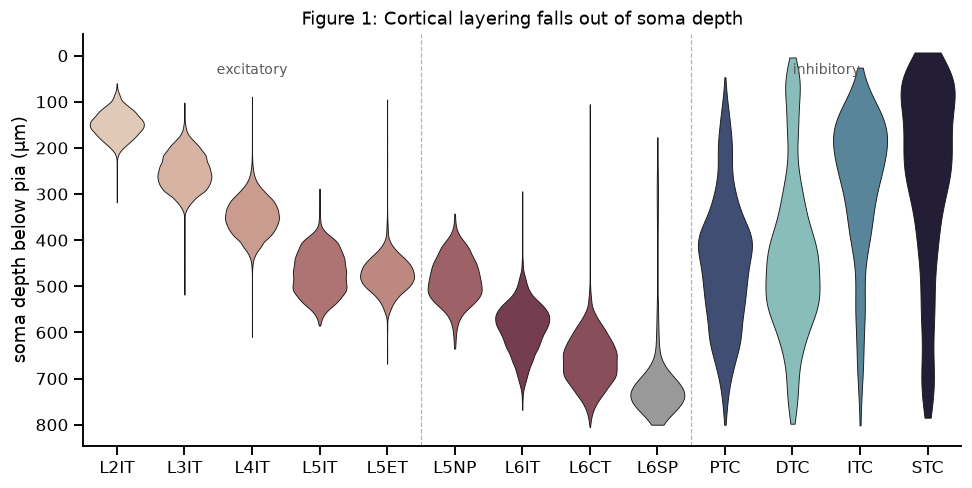

In [13]:
xyz = to_transformed_um(cell_df, "pt_position")
cell_df["depth_um"] = xyz[:, 1]
cell_df["tx_um"], cell_df["tz_um"] = xyz[:, 0], xyz[:, 2]

order = [
    "L2IT",
    "L3IT",
    "L4IT",
    "L5IT",
    "L5ET",
    "L5NP",
    "L6IT",
    "L6CT",
    "L6SP",
    "PTC",
    "DTC",
    "ITC",
    "STC",
]
order = [t for t in order if t in set(cell_df.cell_type.dropna())]

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.violinplot(
    data=cell_df[cell_df.cell_type.isin(order)],
    x="cell_type",
    y="depth_um",
    hue="cell_type",
    order=order,
    hue_order=order,
    palette=PALETTE,
    cut=0,
    linewidth=0.6,
    inner=None,
    legend=False,
    ax=ax,
)
ax.invert_yaxis()
ax.set(
    xlabel="",
    ylabel="soma depth below pia (µm)",
    title="Figure 1: Cortical layering falls out of soma depth",
)
for x in (4.5, 8.5):
    ax.axvline(x, color="0.7", lw=0.8, ls="--")
ax.text(2.0, 40, "excitatory", ha="center", color="0.35", fontsize=9)
ax.text(10.5, 40, "inhibitory", ha="center", color="0.35", fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>The excitatory types stack in layer order — that is the sanity check that the coordinate transform is doing what it claims. The inhibitory types do not, because they are defined by <i>who they target</i>, not by where they sit.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 2:</b> Load <code>EXEMPLAR_L5ET</code> and plot it. Argue from the picture that it is thick-tufted.

</div>

skeleton compartments: {1: 1, 2: 1972, 3: 4529}
(1 = soma, 2 = axon, 3 = dendrite)


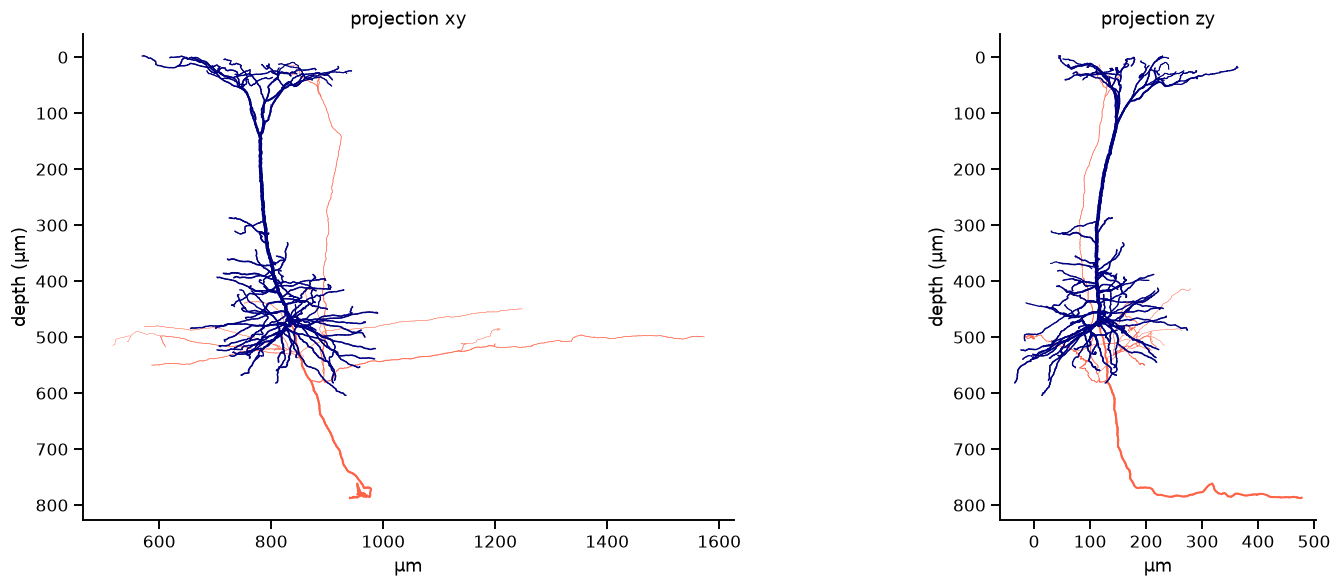

In [14]:
cell = osy.load_cell_from_client(root_id=EXEMPLAR_L5ET, client=client)
cell_t = cell.transform(v1dd_ds.transform("nm").apply)

print(
    "skeleton compartments:",
    cell.skeleton.df["compartment"].value_counts().sort_index().to_dict(),
)
print("(1 = soma, 2 = axon, 3 = dendrite)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, proj in zip(axes, ["xy", "zy"]):
    osy.plot.plot_morphology_2d(
        cell_t,
        projection=proj,
        color="compartment",
        palette={1: "black", 2: "tomato", 3: "navy"},
        linewidth="radius",
        linewidth_norm=(100, 1000),
        widths=(0.25, 2.2),
        ax=ax,
    )
    ax.set(title=f"projection {proj}", xlabel="µm", ylabel="depth (µm)")
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>The apical trunk runs from the soma at roughly 470 µm up to a tuft that reaches the pia, and there is a basal skirt at the soma. That is the thick-tufted ET morphology.
<p><b>The axon is in there too</b>, sprawling laterally. It belongs to the <i>presynaptic</i> side of this cell's story, not the postsynaptic side we care about, and Question 3 has to remove it before measuring anything along the dendrite.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h3> Whose reconstruction has to be right? </h3>
<p>Now the part that governs every number in this module.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 3:</b> Build the presynaptic universe. Join <code>proofreading_status_and_strategy</code> to the cell type table and count, per inhibitory subclass, how many cells have <code>status_axon == True</code>. Then look at <code>strategy_axon</code> and ask what the partially-extended cells are.
<p><i>Call the joined, filtered frame <code>inh_pf</code>.</i>

</div>

In [15]:
pf_df = client.materialize.tables.proofreading_status_and_strategy().get_all(
    split_positions=True
)

pf_ct = pf_df.merge(
    cell_df[["pt_root_id", "classification_system", "cell_type"]],
    on="pt_root_id",
    how="inner",
)

inh_pf = pf_ct.query("status_axon == True and classification_system == 'inhibitory'")

print(f"{len(pf_df):,} cells in the proofreading table")
print(f"{(pf_df.status_axon == True).sum():,} with a proofread axon")
print(f"{len(inh_pf):,} of those are inhibitory\n")
print(pd.crosstab(inh_pf.cell_type, inh_pf.strategy_axon).to_string())

3,335 cells in the proofreading table
1,273 with a proofread axon
465 of those are inhibitory

strategy_axon  axon_fully_extended  axon_partially_extended
cell_type                                                  
DTC                            164                        9
ITC                             72                        1
PTC                            169                        1
STC                             49                        0


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Questions — no code. This is the conceptual core of the module.</b>
<p>You are about to study synapses <i>onto</i> an L5-ET cell.
<ol>
<li><b>Whose reconstruction quality matters, the ET cell's or the interneurons'?</b> Both, differently. The ET cell needs a trustworthy <b>dendrite</b>, which is what makes "we found every synapse onto it" true. The interneurons need trustworthy <b>axons</b>, which is what makes "this synapse came from a PTC" true.
<li><b>A trusted dendrite means every synapse was found. Does it mean every synapse was correctly attributed?</b> No. Segmentation makes <b>merge errors</b> — a fragment of another cell's axon glued onto a soma. The synapse is real and its location is right; the presynaptic identity is wrong. Proofreading removes those merges, which is why <code>status_axon == True</code> is the filter used throughout. Although note that small numbers of errors will remain after proofreading, so always double check that any result isn't based on some small number of potential artifacts.
<li><b>Reconstruction loses thin distal branches more often than thick proximal ones. Suppose one subclass tends to synapse close to its targets' somata and another travels far out along the dendrite. Without the filter, which of the two looks over-represented?</b> The proximal one. Truncation strips the far-travelling subclass's synapses while leaving the close one's largely intact, so an unfiltered analysis reports "inhibition is proximal" <b>whatever the biology does.</b> That is the specific reason this module filters — and note you cannot yet say which label is which, which is the point. Question 2 measures the size of the effect; Question 3 identifies the players.
<li><b>What does the restriction cost?</b> About 95% of the typed inhibitory cells (Figure 2). A much smaller sample, in exchange for labels that mean what they say.
</ol>
<p><code>strategy_axon</code> further splits proofread cells into fully and partially extended, but that is <b>completeness, not correctness</b> — a partially extended axon has had its merges cleaned, so its synapses are still correctly attributed. Completeness only matters when you need a per-axon denominator, which no question here does.

</div>

In [16]:
inh_proofread_ids = root_ids(inh_pf.pt_root_id)
inh_type = inh_pf.set_index("pt_root_id").cell_type  # lookup used from here on
print(f"{len(inh_proofread_ids)} proofread inhibitory axons carried forward")

465 proofread inhibitory axons carried forward


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<hr>
<h2> Question 2 — What lands where? </h2>
<p>Synapses are labelled by what they land on: a dendritic <b>spine</b>, a dendritic <b>shaft</b>, or the <b>soma</b>. The distinction is electrotonic. A spine is a small, electrically isolated compartment, so excitatory input there can summate locally. A synapse on the soma sits right where the axon initial segment decides whether to fire, so it can shunt the whole cell. The textbook claims, stated so we can check them:
<ol>
<li>Excitatory → excitatory synapses are onto <b>spines</b>.
<li>Inhibitory → excitatory synapses are onto <b>shafts</b>.
<li>Synapses onto inhibitory cells are onto <b>shafts</b>.
<li>Basket cells target <b>somata</b> — so one of the four inhibitory labels should own most somatic synapses. Which one?
</ol>

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 1 — assemble the synapse table.</b> Three joins get you from "a list of L5-ET cells" to "one row per synapse, with a compartment and a presynaptic subclass": pull the input synapses, attach the compartment label, attach the presynaptic cell type and restrict to proofread axons. Report the synapse count before and after that last step.
<p><i>The next three cells do them in order — read each one before running it, because the third is a decision and the first two are only plumbing.</i>
<p><i>Names later cells rely on: <code>COHORT</code> and <code>syn</code> for the 15-cell query, <code>COHORT_WIDE</code> and <code>syn_inh</code> for the two-sided one.</i>

</div>

In [17]:
l5et = cell_df.query("cell_type == 'L5ET'").copy()

# Take a set of 15 cells NEAREST the exemplar, not an arbitrary slice. An interneuron's axon
# spans a few hundred microns, and proofreading effort is itself spatially clustered,
# so a cohort spread across the volume gets ~5 proofread inhibitory synapses per cell
# and leaves some with none at all. A local one gets a couple of hundred.
ex = l5et.loc[l5et.pt_root_id == EXEMPLAR_L5ET].iloc[0]
l5et["lateral_um"] = np.hypot(l5et.tx_um - ex.tx_um, l5et.tz_um - ex.tz_um)
l5et = l5et.sort_values("lateral_um")

COHORT = root_ids(l5et.pt_root_id[:15])
print(
    f"{len(l5et):,} L5ET cells; cohort of {len(COHORT)} within "
    f"{l5et.lateral_um.iloc[:15].max():.0f} um of the exemplar"
)

syn = client.materialize.synapse_query(
    post_ids=COHORT, desired_resolution=[1, 1, 1], split_positions=True
)
print(f"{len(syn):,} input synapses onto {len(COHORT)} L5ET cells")

1,127 L5ET cells; cohort of 15 within 30 um of the exemplar
103,421 input synapses onto 15 L5ET cells


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>The compartment label lives in <code>synapse_target_predictions_ssa</code>, a reference table keyed on synapse id. Note it is <code>_ssa</code>, not <code>_ssa_v2</code> — only the former exists at materialization 1196.
<p><code>fetch_tags</code> splits the request into chunks, which is given here rather than explained — there is a reason the server will not take it all at once, and Question 3 makes you find it.

</div>

In [18]:
def fetch_tags(syn_ids, chunk=40_000):
    """Compartment label (spine / shaft / soma) for each synapse id."""
    out = []
    for i in range(0, len(syn_ids), chunk):
        out.append(
            client.materialize.query_table(
                "synapse_target_predictions_ssa",
                filter_in_dict={"target_id": list(map(int, syn_ids[i : i + chunk]))},
                select_columns=["target_id", "tag"],
                merge_reference=False,
                log_warning=False,
            )
        )
    return pd.concat(out, ignore_index=True).rename(columns={"target_id": "id"})

In [19]:
tags = fetch_tags(syn.id.astype("int64").to_numpy())
syn = syn.merge(tags, on="id", how="left")
print(
    f"labelled {syn.tag.notna().sum():,} of {len(syn):,} "
    f"({100 * syn.tag.notna().mean():.1f}%)"
)
print(syn.tag.value_counts().to_string())

labelled 103,383 of 103,421 (100.0%)
tag
spine    69912
shaft    31506
soma      1965


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Now the presynaptic side, and <b>the one real choice in this sequence</b>: restricting to cells with a proofread axon. This restricts the analysis set quite a lot, but still leaves a lot of measured inputs.

</div>

In [20]:
syn["pre_type"] = syn.pre_pt_root_id.map(cell_df.set_index("pt_root_id").cell_type)
syn["pre_class"] = syn.pre_pt_root_id.map(
    cell_df.set_index("pt_root_id").classification_system
)

n_all = len(syn)
n_typed = syn.pre_type.notna().sum()
syn_pf = syn[
    syn.pre_pt_root_id.isin(inh_proofread_ids) | (syn.pre_class == "excitatory")
].copy()

print(f"all input synapses            {n_all:>8,}")
print(f"  ... from a typed cell       {n_typed:>8,}  ({100 * n_typed / n_all:.0f}%)")
print(
    f"  ... after proofread filter  {len(syn_pf):>8,}  ({100 * len(syn_pf) / n_all:.0f}%)"
)

all input synapses             103,421
  ... from a typed cell          8,595  (8%)
  ... after proofread filter     6,861  (7%)


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Most input synapses have <b>no presynaptic label at all</b> — orphan axon fragments with no soma in the volume, so there is nothing to type them by. They are real synapses we simply cannot attribute, and what follows is conditional on the presynaptic cell being identifiable, which is <i>not</i> a random subset of all input.
<p>The set below narrows the query at <i>both</i> ends — <code>pre_ids</code> and <code>post_ids</code> together are a logical AND — so we can sweep far more L5-ET cells while paying only for the synapses we want. <b>It is for the inhibitory subclasses alone.</b> It comes from a different cohort with a different filter than the excitatory synapses above, so counts from the two are not on the same footing. Mixing them is the trap two cells down.

</div>

In [21]:
COHORT_WIDE = root_ids(l5et.pt_root_id[:250])  # still nearest-first

syn_inh = client.materialize.synapse_query(
    pre_ids=inh_proofread_ids,
    post_ids=COHORT_WIDE,
    desired_resolution=[1, 1, 1],
    split_positions=True,
)
syn_inh["tag"] = syn_inh.id.map(
    fetch_tags(syn_inh.id.astype("int64").to_numpy()).set_index("id").tag
)
syn_inh["pre_type"] = syn_inh.pre_pt_root_id.map(inh_type)

print(
    f"{len(syn_inh):,} proofread-inhibitory synapses onto {len(COHORT_WIDE)} L5ET cells"
)
print(syn_inh.pre_type.value_counts().to_string())

47,249 proofread-inhibitory synapses onto 250 L5ET cells
pre_type
PTC    27962
DTC    15268
ITC     2087
STC     1932


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 2:</b> Build the contingency table of presynaptic type × target compartment, and normalize it <b>by row</b>. This is a table where each row will be a cell type, each column will be a compartment, and the value will be the number of synapses in that compartment. You can then ask why the column version — "who owns this compartment?" — is not a question you can answer here.

</div>

In [22]:
inh_types = ["PTC", "DTC", "ITC", "STC"]

# One row per presynaptic group. Rows are normalized independently, so the excitatory
# row (15-cell cohort, typed) and the inhibitory rows (250-cell cohort, proofread) can
# sit in the same table even though they come from different queries -- see below.
exc = syn[(syn.pre_class == "excitatory") & syn.tag.notna()]
inh = syn_inh[syn_inh.pre_type.isin(inh_types) & syn_inh.tag.notna()]

counts = pd.concat(
    [
        pd.crosstab(pd.Series("excitatory (all)", index=exc.index), exc.tag),
        pd.crosstab(inh.pre_type, inh.tag),
    ]
).reindex(index=["excitatory (all)"] + inh_types, columns=["spine", "shaft", "soma"])
counts.insert(0, "n", counts.sum(axis=1))
counts

tag,n,spine,shaft,soma
excitatory (all),2980,2346,602,32
PTC,27959,6873,16586,4500
DTC,15264,3914,11183,167
ITC,2085,413,1633,39
STC,1932,234,1692,6


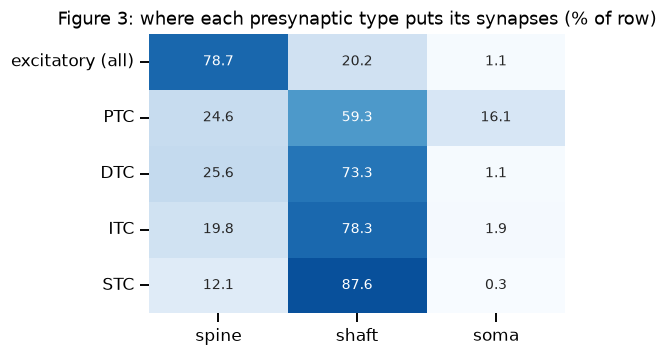

In [23]:
by_row = counts[["spine", "shaft", "soma"]].div(counts.n, axis=0) * 100

fig, ax = plt.subplots(figsize=(5.4, 3.4))
sns.heatmap(
    by_row,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar=False,
    vmin=0,
    vmax=100,
    ax=ax,
    annot_kws={"size": 9},
)
ax.set(
    xlabel="",
    ylabel="",
    title="Figure 3: where each presynaptic type puts its synapses (% of row)",
)
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Read this table across the rows!</b>
<p>A row asks <b>where a given type puts its synapses.</b> It is conditional on the type, so it does not care how well any <i>other</i> type happens to be sampled — which is why the excitatory row and the inhibitory rows can come from different queries and still both be sound. Each row is its own denominator.
<p>Note that because we are limiting our analysis to cell typed neurons with proofread axons, so this leaves out a lot of cells, not only including non-proofread cells, but also pyramidal cells or other projections from outside the volume such as thalamic axons. This means that this tables does not answer the complementary question of where a given compartment <i>recieves</i> synapses from due to this imbalance.
<p>Against the textbook, from the rows alone:
<ol>
<li><b>Excitatory → spine holds</b> — around 79% of attributable excitatory input. Published figures run higher; the proximal dendrite and soma of an L5-ET are genuinely sparsely spined, and the classifier misses some spine necks.
<li><b>Inhibitory → shaft holds</b>, and increasingly so along <code>PTC</code> → <code>DTC</code> → <code>ITC</code> → <code>STC</code>.
<li>Untestable here — our postsynaptic cells are all excitatory by construction.
<li><b>Only <code>PTC</code> targets somata to any real extent</b> — around 16% of its synapses, against roughly 1% for the other three. That is claim 4, made safely from a row: not "somata are mostly PTC" (a column claim we cannot support) but "PTC is the one subclass that puts a substantial share of its output on somata."
</ol>
<p>Worth noticing in passing: the somatic share falls away sharply after <code>PTC</code> while the shaft share climbs steadily to <code>STC</code>. That ordering shows up again in Question 3, measured geometrically instead of from labels.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Before the statistics, one picture. Here are the exemplar's input synapses on its own morphology, coloured by presynaptic subclass — one cell, not the result.

</div>

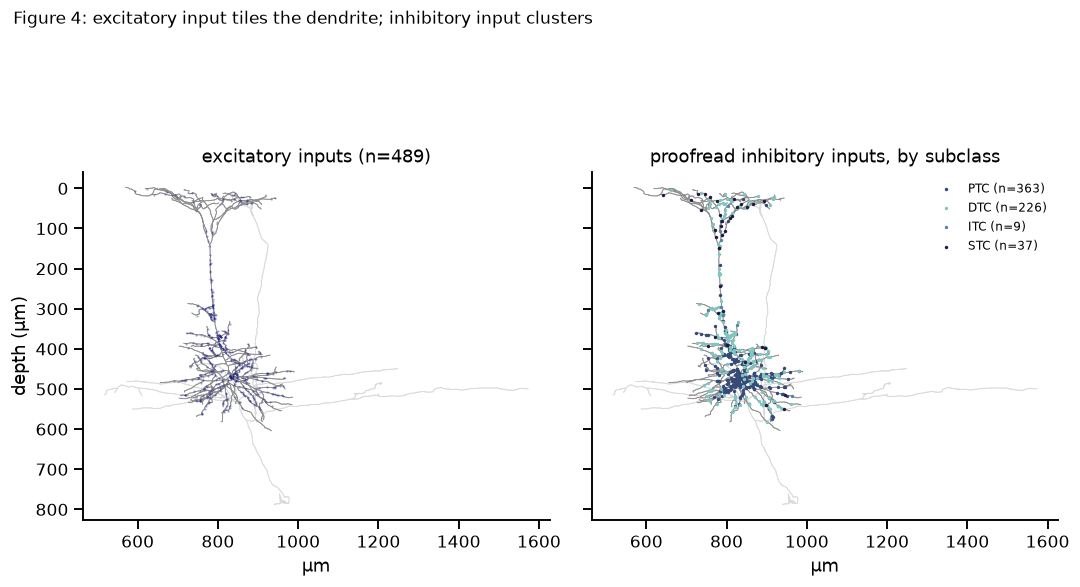

In [24]:
cell_syn = osy.load_cell_from_client(
    root_id=EXEMPLAR_L5ET, client=client, synapses=True, include_partner_root_id=True
)
post = cell_syn.annotations.post_syn.df.copy()
post["tag"] = post.index.map(tags.set_index("id").tag)
post["pre_type"] = post.pre_pt_root_id.map(cell_df.set_index("pt_root_id").cell_type)
post["is_pf"] = post.pre_pt_root_id.isin(inh_proofread_ids)

xyz_s = v1dd_ds.transform("nm").apply(
    post[["ctr_pt_position_x", "ctr_pt_position_y", "ctr_pt_position_z"]].values
)
post["sx_um"], post["sy_um"] = xyz_s[:, 0], xyz_s[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
for ax in axes:
    osy.plot.plot_morphology_2d(
        cell_syn.transform(v1dd_ds.transform("nm").apply),
        projection="xy",
        color="compartment",
        palette={1: "0.2", 2: "0.85", 3: "0.55"},
        linewidth=0.6,
        ax=ax,
    )
    ax.set(xlabel="µm")

exc = post[post.pre_type.isin(["L2IT", "L3IT", "L4IT", "L5IT", "L5ET", "L6IT", "L6CT"])]
axes[0].scatter(exc.sx_um, exc.sy_um, s=2, c="navy", alpha=0.35, lw=0, zorder=5)
axes[0].set(title=f"excitatory inputs (n={len(exc):,})", ylabel="depth (µm)")

for t in inh_types:
    m = post[(post.pre_type == t) & post.is_pf]
    axes[1].scatter(
        m.sx_um,
        m.sy_um,
        s=5,
        color=PALETTE.get(t, "k"),
        label=f"{t} (n={len(m)})",
        lw=0,
        zorder=6,
    )
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
axes[1].set(title="proofread inhibitory inputs, by subclass")
fig.suptitle(
    "Figure 4: excitatory input tiles the dendrite; inhibitory input clusters",
    y=0.98,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Already visible by eye: the excitatory cloud covers the whole arbor, while PTC piles up around the soma. That is the result the rest of the exercise will make quantitative.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<hr>
<h2> Question 3 — Where along the dendrite? </h2>
<p>"Shaft" covers a synapse 20 µm from the soma and one 400 µm out on the apical tuft. Electrically those are different worlds, so a compartment label is not enough — we need a position along the arbor.
<p>The right measure is <b>geodesic distance</b>: path length through the dendrite from the soma. It is what sets how much of a synapse's effect survives the trip, and it needs a <b>skeleton</b>, which is why this question works on the one screened cell where we have one.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 1 — get the distances.</b> Compute geodesic distance to the soma for every input synapse on <code>EXEMPLAR_L5ET</code> — <b>masking to the dendrite first</b>, because on this cell the axon is about a third of the skeleton and leaving it in lets a synapse be "reached" the wrong way.
<p><i>Names later cells rely on: <code>dend</code> for the masked cell, <code>anno</code> for its <code>post_syn</code> annotation, and <code>syn_df</code> for the per-synapse frame.</i>

</div>

compartments: {1: 1, 2: 1972, 3: 4529}
6,502 skeleton vertices -> 4,530 after dropping axon


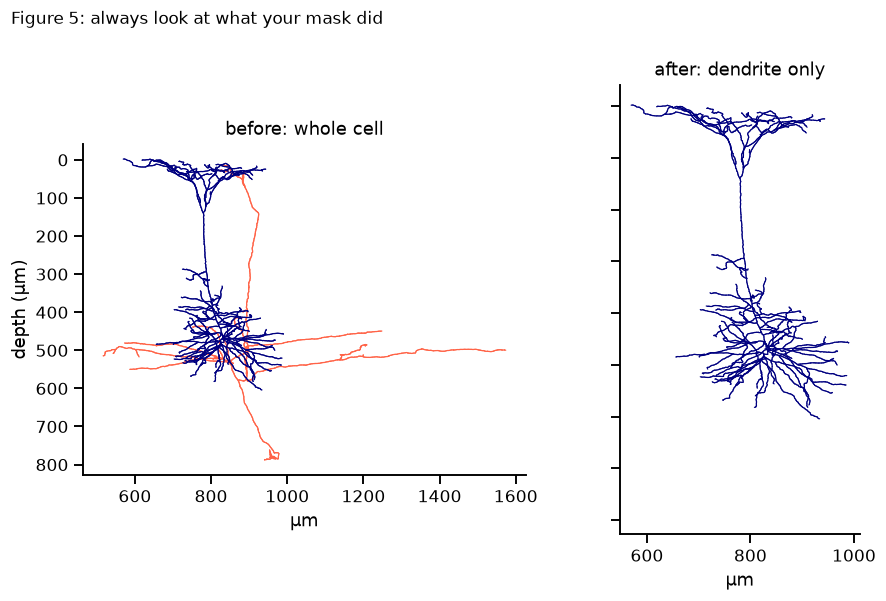

In [25]:
print(
    "compartments:",
    cell_syn.skeleton.df["compartment"].value_counts().sort_index().to_dict(),
)

dend = cell_syn.s.apply_mask(cell_syn.skeleton.df["compartment"] != osy.SWC_AXON)
print(
    f"{cell_syn.skeleton.n_vertices:,} skeleton vertices -> "
    f"{dend.skeleton.n_vertices:,} after dropping axon"
)

fig, axes = plt.subplots(1, 2, figsize=(9, 5.5), sharey=True)
for ax, obj, t in zip(
    axes, [cell_syn, dend], ["before: whole cell", "after: dendrite only"]
):
    osy.plot.plot_morphology_2d(
        obj.transform(v1dd_ds.transform("nm").apply),
        projection="xy",
        color="compartment",
        palette={1: "black", 2: "tomato", 3: "navy"},
        linewidth=0.8,
        ax=ax,
    )
    ax.set(title=t, xlabel="µm")
axes[0].set_ylabel("depth (µm)")
fig.suptitle(
    "Figure 5: always look at what your mask did",
    y=0.99,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

In [26]:
anno = dend.annotations.post_syn
syn_df = anno.df.copy()
syn_df["geodesic_um"] = anno.distance_to_root() / 1_000.0
syn_df["pre_type"] = syn_df.pre_pt_root_id.map(
    cell_df.set_index("pt_root_id").cell_type
)
syn_df["pre_class"] = syn_df.pre_pt_root_id.map(
    cell_df.set_index("pt_root_id").classification_system
)
syn_df["is_pf_inh"] = syn_df.pre_pt_root_id.isin(inh_proofread_ids)
syn_df["tag"] = syn_df.index.map(tags.set_index("id").tag)
syn_df = syn_df.dropna(subset=["geodesic_um"])
print(f"{len(syn_df):,} input synapses on the dendrite")
print(syn_df[syn_df.is_pf_inh].pre_type.value_counts().to_string())

15,395 input synapses on the dendrite
pre_type
PTC    363
DTC    226
STC     37
ITC      9


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 2 — the distribution.</b> Histogram geodesic distance for the proofread inhibitory inputs, split by the four subclasses. Do they sit in different places along the dendrite?

</div>

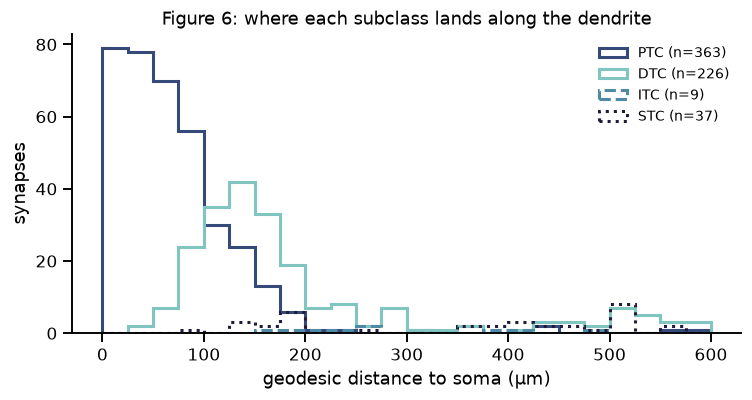

In [27]:
bins = np.arange(0, 601, 25)
inh = syn_df[syn_df.is_pf_inh & syn_df.pre_type.isin(inh_types)]
# Four cool-toned colours are hard to tell apart as overlapping steps; add a linestyle.
DASH = {"PTC": "-", "DTC": "-", "ITC": "--", "STC": ":"}

fig, ax = plt.subplots(figsize=(7, 3.8))
for t in inh_types:
    g = inh[inh.pre_type == t].geodesic_um
    if len(g) < 5:
        continue
    ax.hist(
        g,
        bins=bins,
        histtype="step",
        lw=2,
        ls=DASH[t],
        color=PALETTE.get(t, "k"),
        label=f"{t} (n={len(g)})",
    )
ax.set(
    xlabel="geodesic distance to soma (µm)",
    ylabel="synapses",
    title="Figure 6: where each subclass lands along the dendrite",
)
ax.legend(frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 3 — put numbers on it.</b> Median and quartiles of geodesic distance per subclass.

</div>

In [28]:
inh2 = syn_df[syn_df.is_pf_inh & syn_df.pre_type.isin(inh_types)]
pd.DataFrame(
    {
        "n": inh2.groupby("pre_type").size(),
        "median": inh2.groupby("pre_type").geodesic_um.median(),
        "p25": inh2.groupby("pre_type").geodesic_um.quantile(0.25),
        "p75": inh2.groupby("pre_type").geodesic_um.quantile(0.75),
    }
).reindex(inh_types).round(1)

,n,median,p25,p75
pre_type,,,,
PTC,363,58.6,29.7,92.7
DTC,226,152.6,115.0,226.5
ITC,9,260.3,206.4,382.9
STC,37,412.7,195.5,511.3


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>A clean monotonic ordering: <code>PTC</code> closest to the soma, then <code>DTC</code>, then <code>ITC</code>, then <code>STC</code> furthest out. That is the same ranking the compartment table implied in Question 2, recovered from an entirely different measurement — and this time as a distance rather than a category.
<p>Two cautions before believing it too hard. <b><code>ITC</code> has a single-digit count on this cell</b>, so its median is a curiosity rather than a measurement; the next question fixes that by pooling over many targets. And <b>a raw histogram is partly a picture of where the dendrite is</b> — more synapses at 100 µm may only mean more dendrite at 100 µm. That confound does not disturb the <i>ranking</i> here, because all four subclasses are measured against the same dendrite, but it matters the moment you want an absolute density. The optional section at the end takes it on.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<hr>
<h2> Question 4 — Build a cheap frame, and find out what it costs </h2>
<p>Question 3 did it the right way, and the cost is visible: one skeleton, one cell. The next question needs <i>hundreds</i> of target cells, so geodesic distance is out of reach.
<p>The way round is a frame anchored on the target's <b>soma position</b>, which is just a column — <code>r_theta</code> from the setup. But it is an approximation, so before spending it we measure what it costs, on the one cell where both measures exist.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 1 — how good is straight-line distance?</b> Compute <b>r</b> for the same synapses and scatter it against the geodesic distance you already have.
<p><b>Predict first, in writing:</b> as synapses get further from the soma, does the approximation get better or worse?

</div>

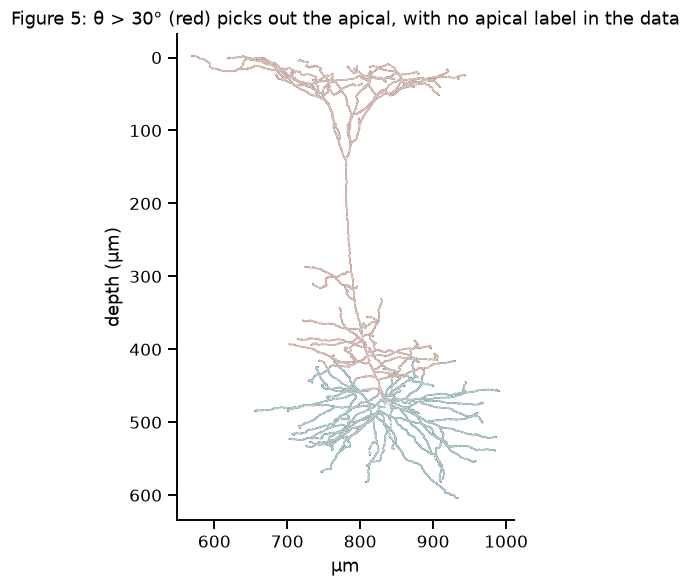

In [29]:
root_xyz = dend.s.root_location
soma_um = v1dd_ds.transform("nm").apply(root_xyz.reshape(1, 3))[0]
syn_um = v1dd_ds.transform("nm").apply(anno.vertices)
syn_df["r_um"], syn_df["theta_deg"] = r_theta(syn_um, soma_um)

# Does theta mean what we think? There is no apical label in this dataset to check
# against, so colour the skeleton by it and look.
vert_um = v1dd_ds.transform("nm").apply(dend.skeleton.vertices)
_, vert_theta = r_theta(vert_um, soma_um)

fig, ax = plt.subplots(figsize=(5.2, 5.5))
osy.plot.plot_morphology_2d(
    dend.transform(v1dd_ds.transform("nm").apply),
    projection="xy",
    color="compartment",
    palette={1: "0.3", 3: "0.8"},
    linewidth=0.7,
    ax=ax,
)
ax.scatter(
    vert_um[:, 0],
    vert_um[:, 1],
    s=1.4,
    c=np.where(vert_theta > 30, "#B4472E", "#0E6E78"),
    lw=0,
)
ax.set(
    title="Figure 5: θ > 30° (red) picks out the apical, with no apical label in the data",
    xlabel="µm",
    ylabel="depth (µm)",
)
sns.despine()
plt.tight_layout()
plt.show()

In [30]:
d = syn_df[syn_df.r_um > 1].copy()
d["tortuosity"] = d.geodesic_um / d.r_um

r_pearson = np.corrcoef(d.geodesic_um, d.r_um)[0, 1]
r_spear = stats.spearmanr(d.geodesic_um, d.r_um).statistic
print(f"Pearson r = {r_pearson:.4f}   Spearman = {r_spear:.4f}")
print(
    f"tortuosity: median {d.tortuosity.median():.3f}, "
    f"p10 {d.tortuosity.quantile(0.1):.3f}, p90 {d.tortuosity.quantile(0.9):.3f}"
)

Pearson r = 0.9889   Spearman = 0.9507
tortuosity: median 1.218, p10 1.091, p90 1.663


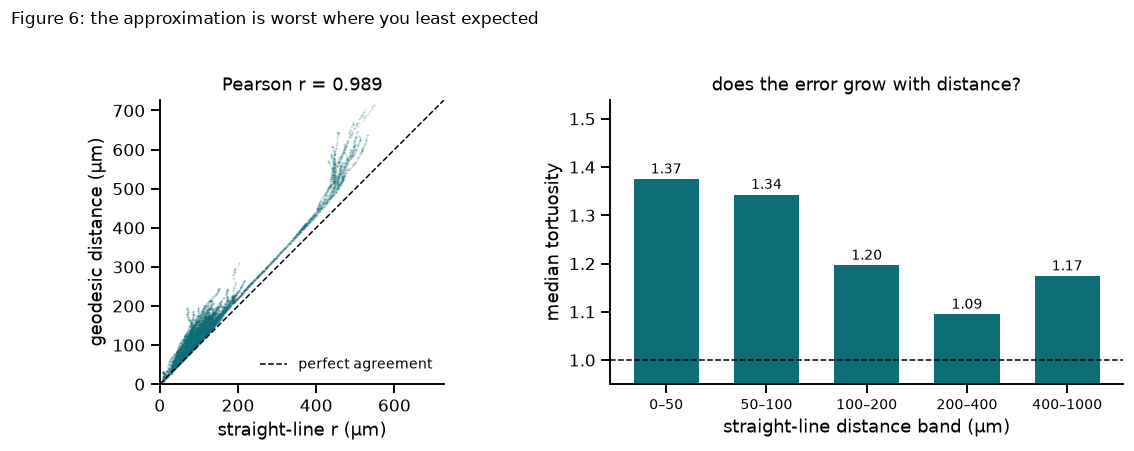

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].scatter(d.r_um, d.geodesic_um, s=1.5, alpha=0.12, c="#0E6E78", lw=0)
lim = [0, max(d.r_um.max(), d.geodesic_um.max()) * 1.02]
axes[0].plot(lim, lim, "k--", lw=1, label="perfect agreement")
axes[0].set(
    xlim=lim,
    ylim=lim,
    xlabel="straight-line r (µm)",
    ylabel="geodesic distance (µm)",
    aspect="equal",
    title=f"Pearson r = {r_pearson:.3f}",
)
axes[0].legend(frameon=False, fontsize=9)

band_edges = [0, 50, 100, 200, 400, 1000]
labels = [f"{a}–{b}" for a, b in zip(band_edges[:-1], band_edges[1:])]
d["band"] = pd.cut(d.r_um, band_edges, labels=labels)
med = d.groupby("band", observed=True).tortuosity.median()
axes[1].bar(range(len(med)), med.values, color="#0E6E78", width=0.65)
axes[1].axhline(1, color="k", lw=1, ls="--")
axes[1].set_xticks(range(len(med)))
axes[1].set_xticklabels(med.index, fontsize=9)
axes[1].set(
    xlabel="straight-line distance band (µm)",
    ylabel="median tortuosity",
    ylim=(0.95, max(1.5, med.max() * 1.12)),
    title="does the error grow with distance?",
)
for i, v in enumerate(med.values):
    axes[1].text(i, v + 0.012, f"{v:.2f}", ha="center", fontsize=9)
fig.suptitle(
    "Figure 6: the approximation is worst where you least expected",
    y=1.02,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>At least here, error shrinks with distance.</b>
<p>The reason is geometry. A synapse 400 µm out is on the apical tuft, reached by a nearly straight trunk — path length is close to the straight line. A synapse 30 µm out is on a twisting local basal branch that wanders half again as far as the direct route. So the approximation is <i>best exactly where the compartment story is most interesting</i>, and worst close in, within a few tens of microns of the soma.
<p>That last clause is a genuine caveat, not a reassurance: proximal r is systematically an underestimate of electrotonic distance. It does not threaten a <i>comparison</i> between subclasses, which is what Question 4 makes, but it would threaten a quantitative claim about decay.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 2 — does the ranking survive?</b> Recompute the subclass comparison with <b>r</b> and <b>θ</b> alongside geodesic. An approximation that blurs the axis but preserves the ordering is fine for comparing populations; it would not be fine for a quantitative claim about decay.

</div>

In [32]:
inh2 = syn_df[syn_df.is_pf_inh & syn_df.pre_type.isin(inh_types)]
comp = (
    pd.DataFrame(
        {
            "n": inh2.groupby("pre_type").size(),
            "median geodesic": inh2.groupby("pre_type").geodesic_um.median(),
            "median r": inh2.groupby("pre_type").r_um.median(),
            "median θ": inh2.groupby("pre_type").theta_deg.median(),
            "% apical (θ>30°)": 100
            * inh2.assign(a=inh2.theta_deg > 30).groupby("pre_type").a.mean(),
        }
    )
    .reindex(inh_types)
    .round(1)
)
comp

,n,median geodesic,median r,median θ,% apical (θ>30°)
pre_type,,,,,
PTC,363,58.6,43.7,5.2,33.3
DTC,226,152.6,112.7,51.6,65.0
ITC,9,260.3,191.8,75.4,88.9
STC,37,412.7,377.2,76.1,91.9


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>The <b>ordering is preserved</b> — whichever subclass is proximal in geodesic terms is proximal in r. The magnitudes compress slightly, as Figure 7 predicted. That is exactly the licence the rest of this question needs: an approximation that preserves ranking is fine for comparing populations, and would not be fine for a quantitative claim about electrotonic decay. Q4 makes only the first kind of claim.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Choosing the exemplars.</b> Filter on <code>status_axon</code> for correctness as always, then <i>screen</i> on <code>axon_fully_extended</code> plus a high synapse count. Completeness is not needed for the synapses to be valid — it is a quality heuristic, because an axon that stopped early samples fewer of its targets and possibly a skewed subset.

</div>

In [33]:
soma_lookup = cell_df.set_index("pt_root_id")[
    ["tx_um", "depth_um", "tz_um", "cell_type", "classification_system"]
]

fully = pf_ct.query(
    "strategy_axon == 'axon_fully_extended' and classification_system == 'inhibitory'"
)
print(fully.cell_type.value_counts().to_string())

cell_type
PTC    169
DTC    164
ITC     72
STC     49


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 3 — start with one of each.</b> Pull the output synapses of one <code>PTC</code> and one <code>DTC</code>, and place every synapse in the frame of <i>the target it landed on</i>. Plot the two side by side.
<p>One cloud on its own is uninterpretable — a shape only means something against a comparison. Two cells cost two queries and about a second, and they give you the answer before any of the plumbing that follows.

</div>

In [34]:
EXEMPLAR_PTC = int(root_ids(fully.query("cell_type == 'PTC'").pt_root_id)[0])
EXEMPLAR_DTC = int(root_ids(fully.query("cell_type == 'DTC'").pt_root_id)[0])


def outputs_in_target_frame(pre_ids):
    """Every synapse these cells make, in (r, theta) about each target's own soma."""
    s = client.materialize.synapse_query(
        pre_ids=np.atleast_1d(pre_ids).astype("uint64"),
        desired_resolution=[1, 1, 1],
        split_positions=True,
    )
    s = s.join(soma_lookup, on="post_pt_root_id", how="inner")
    if len(s) == 0:
        return s
    pts = v1dd_ds.transform("nm").apply(
        s[["ctr_pt_position_x", "ctr_pt_position_y", "ctr_pt_position_z"]].values
    )
    # r_theta takes one soma; here every synapse has its own, so subtract first and
    # hand it a zero origin.
    s["r_um"], s["theta_deg"] = r_theta(
        pts - s[["tx_um", "depth_um", "tz_um"]].values, np.zeros(3)
    )
    return s

PTC: 1,360 synapses onto 401 typed targets, median r = 26 um, theta = -0 deg
DTC: 3,184 synapses onto 1,878 typed targets, median r = 101 um, theta = +20 deg


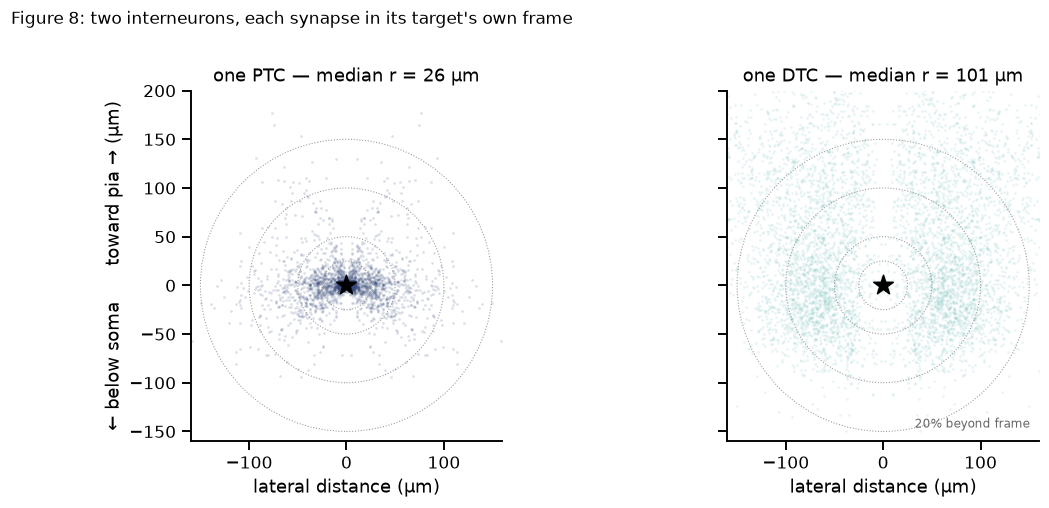

In [35]:
one = {
    t: outputs_in_target_frame(rid)
    for t, rid in [("PTC", EXEMPLAR_PTC), ("DTC", EXEMPLAR_DTC)]
}
for t, d in one.items():
    print(
        f"{t}: {len(d):,} synapses onto {d.post_pt_root_id.nunique():,} typed targets, "
        f"median r = {d.r_um.median():.0f} um, theta = {d.theta_deg.median():+.0f} deg"
    )


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, t in zip(axes, ["PTC", "DTC"]):
    cloud(
        ax,
        one[t],
        f"one {t} — median r = {one[t].r_um.median():.0f} µm",
        PALETTE.get(t, "k"),
    )
axes[0].set_ylabel("← below soma      toward pia → (µm)")
fig.suptitle(
    "Figure 8: two interneurons, each synapse in its target's own frame",
    y=1.0,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>There it is, on two cells.</b> One label sits tight against the soma; the other sits several times further out and leans toward the pia. Neither cloud knows anything about <i>which</i> target each synapse landed on — that was divided out by construction.
<p>Two cells is not a result, though. The rest of this question asks whether they were representative — which needs twenty, and twenty is where the server starts saying no.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 4 — now scale it the obvious way, and watch it break.</b> You need this for ~20 interneurons. Put all twenty ids into a single query. <b>Write down what you expect before you run it.</b>

</div>

In [36]:
many = root_ids(fully.query("cell_type == 'PTC'").pt_root_id)[:40]
try:
    client.materialize.synapse_query(
        pre_ids=many, desired_resolution=[1, 1, 1], split_positions=True
    )
    print("...that worked, which it usually does not")
except Exception as e:
    print(f"{type(e).__name__}: {str(e)[:160]}")

HTTPError: 502 Server Error: Bad Gateway for url: https://api.em.brain.allentech.org/materialize/api/v3/datastack/v1dd_public/version/1196/table/synapses_v1dd/query?return


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Two things to take from that failure.</b>
<p><b>It is not a bug in your code and not a bad root id.</b> The traceback ends in <code>requests.HTTPError</code>, not a <code>KeyError</code> — your request was well-formed and the <i>server</i> refused it. A 502 with HTML in the body is a proxy giving up on a response that got too large. Recognising which layer failed is the transferable skill.
<p><b>The limit is on response size, not id count.</b> Twenty of these cells return fine; forty do not. Twenty cells with bigger axons might also not. So "find a batch size that works" is a fragile fix — pick one comfortably inside the limit and handle failure gracefully.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 5 — fix it.</b> Batch the request and concatenate. Ten ids per call sits inside the limit and costs a tenth of the round trips; since <code>synapse_query</code> returns <code>pre_pt_root_id</code> on every row, a <code>groupby</code> recovers per-cell results afterwards. The design choice worth making deliberately is what to do when a batch <i>does</i> fail — discarding all ten is wasteful when usually nine are fine.

</div>

In [37]:
import time


def collect(pre_ids, chunk=10, pause=3.0):
    """Query in batches, falling back to one-at-a-time when a batch fails.

    Ten ids per request sits inside the limit and costs a tenth of the round trips.
    If a batch does fail, retrying it cell-by-cell isolates the bad one instead of
    discarding all ten. Returns (frame, ids that never came back).
    """
    frames, failed = [], []
    for i in range(0, len(pre_ids), chunk):
        batch = [int(p) for p in pre_ids[i : i + chunk]]
        try:
            frames.append(outputs_in_target_frame(batch))
        except Exception:
            time.sleep(pause)
            for pid in batch:
                try:
                    frames.append(outputs_in_target_frame([pid]))
                except Exception:
                    failed.append(pid)
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return out, failed


N_PER_SUBCLASS = 8
panel = {}
for t in ["PTC", "DTC"]:
    ids = root_ids(fully.query("cell_type == @t").pt_root_id)[:N_PER_SUBCLASS]
    df, failed = collect(ids)
    df["pre_type"] = t
    panel[t] = df
    print(
        f"{t}: {len(df):,} synapses from {df.pre_pt_root_id.nunique()} cells"
        + (f"  [failed: {failed}]" if failed else "")
    )

allpre = pd.concat(panel.values(), ignore_index=True)

PTC: 22,736 synapses from 8 cells
DTC: 20,941 synapses from 8 cells


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Two refinements in there worth insisting on, because they are what separates a script that survives a real dataset from one that does not. <b>Retry with a pause</b>, because a 502 can also be transient and a twenty-minute loop that dies on iteration 17 has wasted twenty minutes. And <b>collect failures rather than raising</b>, so one bad cell costs you one cell rather than the whole run.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 6 — do the two example cells hold up?</b> Redraw the same clouds from the full panel.

</div>

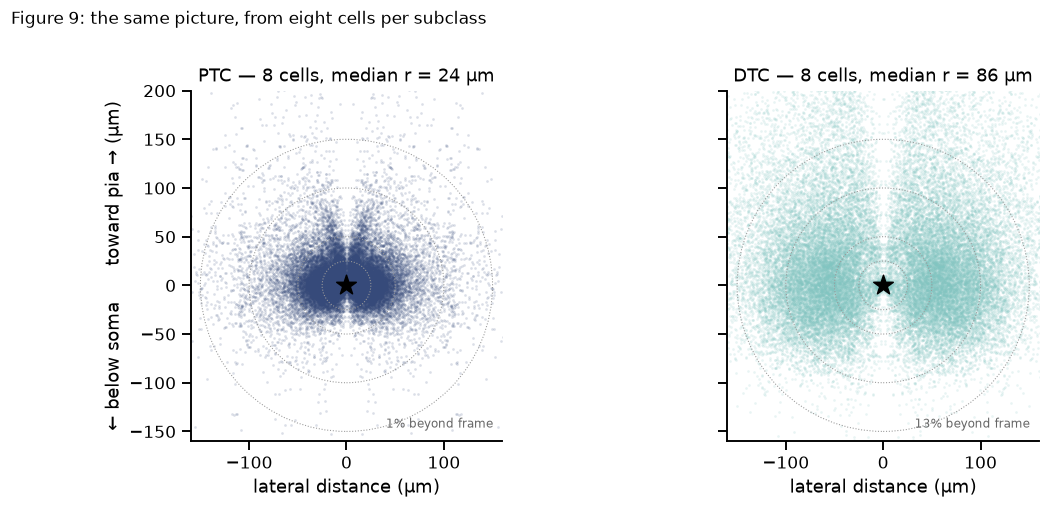

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, t in zip(axes, ["PTC", "DTC"]):
    df = panel[t]
    cloud(
        ax,
        df,
        f"{t} — {df.pre_pt_root_id.nunique()} cells, "
        f"median r = {df.r_um.median():.0f} µm",
        PALETTE.get(t, "k"),
    )
axes[0].set_ylabel("← below soma      toward pia → (µm)")
fig.suptitle(
    "Figure 9: the same picture, from eight cells per subclass",
    y=1.0,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>They hold.</b> Eight cells per subclass reproduce the separation the two exemplars showed — the first evidence that Task 2 was not a lucky pair.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 7 — the repeatability question.</b> Pooling over targets could still hide the thing we actually want to know. Split by target: for each (interneuron, target) pair compute a median r, and look at the spread <i>within</i> one interneuron. Does a single cell do the same thing to all of its targets, or is it proximal on some and distal on others?
<p>Make a dataframe where each row is a proofread interneuron (with known type) and there are columns for the median radial distance to soma as well as the interquartile interval (25-to-75th percentile range) of the radial distance distribution. Plot 1) a histogram of the median distance distribution by interneuron subclass and 2) a plot showing median and IQR values for each interneuron as a dot with errorbars.

</div>

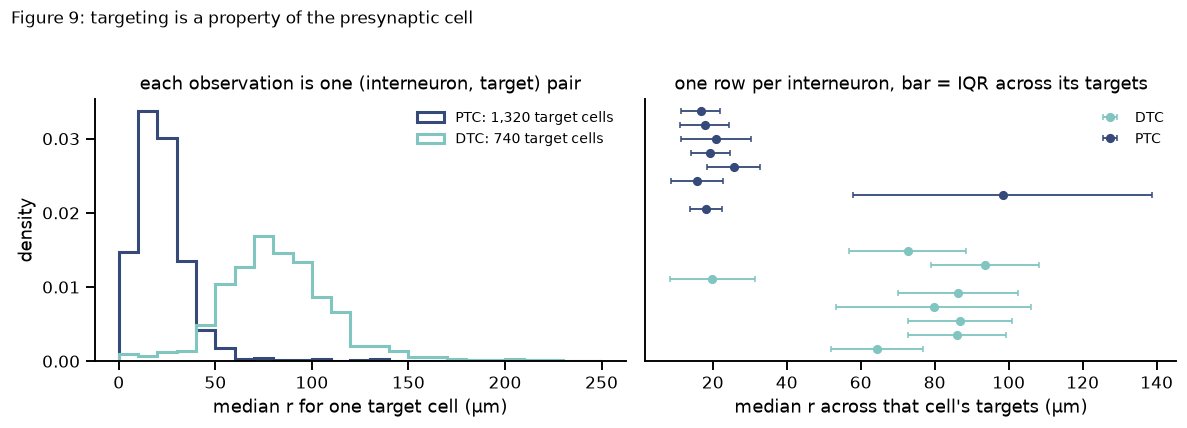

,pre,subclass,n_targets,median_r,iqr
0,864691132558474249,PTC,174,18.2,8.6
1,864691132564013006,PTC,18,98.3,81.0
2,864691132577952020,PTC,191,15.8,13.9
3,864691132579592205,PTC,443,25.7,14.4
4,864691132675700437,PTC,160,19.4,10.5
5,864691132682921775,PTC,89,20.8,19.1
6,864691132717868815,PTC,107,17.8,13.4
7,864691132831272057,PTC,138,16.7,10.7
8,864691132536286810,DTC,29,64.3,24.8
9,864691132536904794,DTC,127,86.1,26.6


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rows = []
for t in ["PTC", "DTC"]:
    df = panel[t]
    per_t = (
        df.groupby(["pre_pt_root_id", "post_pt_root_id"])
        .r_um.agg(["size", "median"])
        .query("size >= 5")
    )
    axes[0].hist(
        per_t["median"],
        bins=np.arange(0, 260, 10),
        histtype="step",
        lw=2,
        density=True,
        color=PALETTE.get(t, "k"),
        label=f"{t}: {len(per_t):,} target cells",
    )
    for pre, g in per_t.groupby("pre_pt_root_id"):
        rows.append(
            {
                "pre": pre,
                "subclass": t,
                "n_targets": len(g),
                "median_r": g["median"].median(),
                "iqr": g["median"].quantile(0.75) - g["median"].quantile(0.25),
            }
        )
axes[0].set(
    xlabel="median r for one target cell (µm)",
    ylabel="density",
    title="each observation is one (interneuron, target) pair",
)
axes[0].legend(frameon=False, fontsize=9)

per_cell = pd.DataFrame(rows)
for i, (t, g) in enumerate(per_cell.groupby("subclass")):
    axes[1].errorbar(
        g.median_r,
        np.arange(len(g)) + i * 10,
        xerr=g.iqr / 2,
        fmt="o",
        color=PALETTE.get(t, "k"),
        ms=5,
        lw=1.2,
        capsize=2,
        label=t,
    )
axes[1].set(
    xlabel="median r across that cell's targets (µm)",
    yticks=[],
    title="one row per interneuron, bar = IQR across its targets",
)
axes[1].legend(frameon=False, fontsize=9)
fig.suptitle(
    "Figure 9: targeting is a property of the presynaptic cell",
    y=1.02,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()
per_cell.round(1)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>This is the answer to the question the module is named after.</b> A single PTC touches hundreds of different target cells and does substantially the same thing to each: its per-target median r has an IQR of a few tens of microns, against a PTC-vs-DTC separation several times larger. The subclass label is not a summary of a heterogeneous bag — it is predicting a real, repeatable property of individual cells.

</div>

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<p><b>Task 8 — split by target cell type.</b> Does an interneuron treat every kind of target the same? Measure the median radial distance as a function of <i>both</i> presynaptic interneuron subclass and postsynaptic target class. For PTC and DTC cells, how does their medial targeting distance vary with target?

</div>

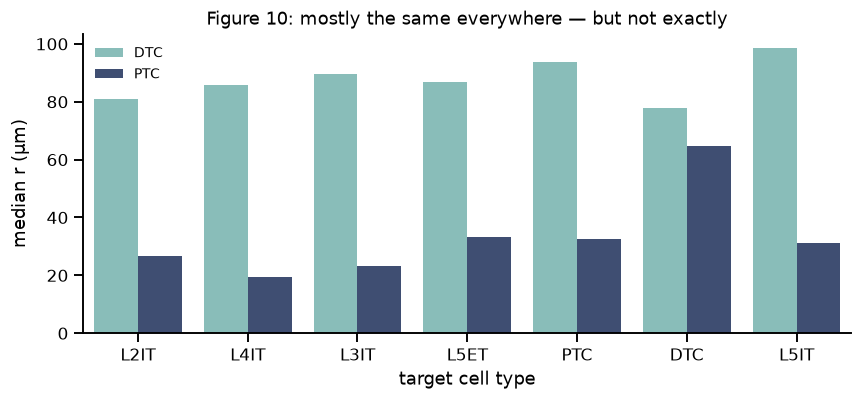

pre_type,DTC,PTC
cell_type,,
DTC,77.8,64.6
L2IT,80.9,26.7
L3IT,89.7,23.1
L4IT,85.6,19.4
L5ET,86.8,33.2
L5IT,98.6,31.0
PTC,93.7,32.4


In [ ]:
tt = (
    allpre.groupby(["pre_type", "cell_type"])
    .agg(n=("r_um", "size"), median_r=("r_um", "median"))
    .query("n >= 200")
    .reset_index()
)
common = tt.groupby("cell_type").n.sum().sort_values(ascending=False).head(7).index
tt = tt[tt.cell_type.isin(common)]

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(
    data=tt,
    x="cell_type",
    y="median_r",
    hue="pre_type",
    palette={k: PALETTE.get(k, "C0") for k in ["PTC", "DTC"]},
    order=common,
    ax=ax,
)
ax.set(
    xlabel="target cell type",
    ylabel="median r (µm)",
    title="Figure 10: mostly the same everywhere — but not exactly",
)
ax.legend(frameon=False, title="", fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()
tt.pivot(index="cell_type", columns="pre_type", values="median_r").round(1)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p>Largely flat, which is the point: the subclass signature travels across target types. The residual structure is worth arguing about, though — PTC tends to sit a little further out on larger-somad targets like L5ET than on L4IT. Is that a different targeting rule, or just that a bigger soma pushes the near-soma shell outward? A good prompt for whether r should be normalized by target soma radius, which <code>cell_df.volume</code> would let you try.

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<hr>
<h3> Optional — the denominator problem </h3>
<p><i>Not needed for anything above, but useful for thinking about the data.</i>
<p>Every distance histogram in this module is partly a picture of <b>where the dendrite is</b>. More synapses at 100 µm may just mean more dendrite at 100 µm. It did not distort the comparisons here, because two subclasses measured on the same cells share the same denominator and it largely cancels — but the moment you compare <i>across</i> cells, or ask an absolute question like "how dense is inhibition on the tuft", it stops cancelling.
<p>The fix on a cell with a skeleton is to divide by <b>µm of dendrite per bin</b>. Run the cell below and compare the middle panel to the right one: the raw counts are dominated by the shape of the denominator.

</div>

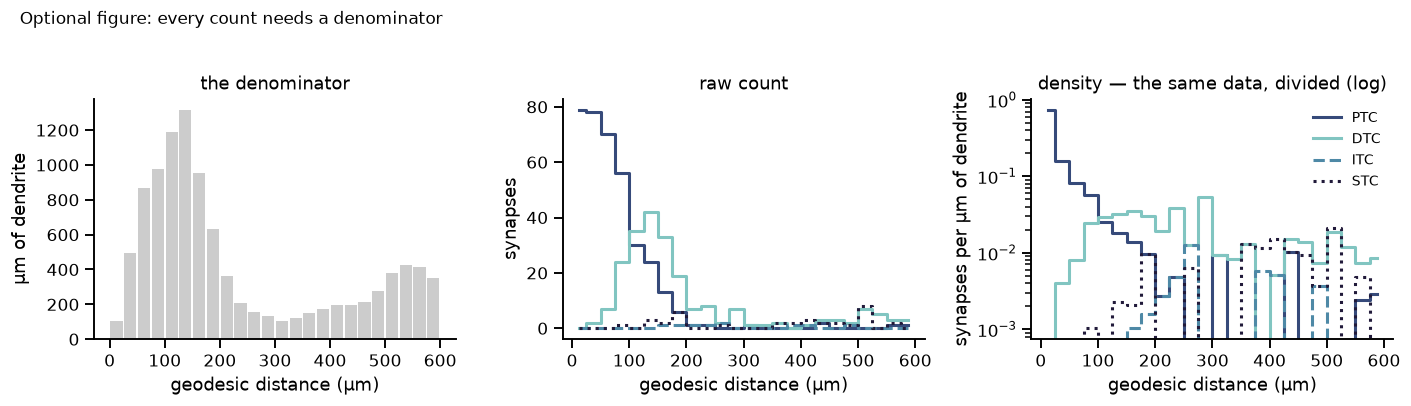

In [ ]:
bins = np.arange(0, 601, 25)
inh = syn_df[syn_df.is_pf_inh & syn_df.pre_type.isin(inh_types)]
DASH = {"PTC": "-", "DTC": "-", "ITC": "--", "STC": ":"}

vert_dist = dend.skeleton.distance_to_root() / 1_000.0
vert_len = dend.skeleton.half_edge_length / 1_000.0
dendrite_um, _ = np.histogram(vert_dist, bins=bins, weights=vert_len)
centers = 0.5 * (bins[:-1] + bins[1:])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].bar(centers, dendrite_um, width=22, color="0.8")
axes[0].set(
    xlabel="geodesic distance (µm)", ylabel="µm of dendrite", title="the denominator"
)
for t in inh_types:
    g = inh[inh.pre_type == t].geodesic_um
    if len(g) < 5:
        continue
    n, _ = np.histogram(g, bins=bins)
    axes[1].step(
        centers, n, where="mid", lw=2, color=PALETTE.get(t, "k"), ls=DASH[t], label=t
    )
    with np.errstate(divide="ignore", invalid="ignore"):
        dens = np.where(dendrite_um > 20, n / dendrite_um, np.nan)
    axes[2].step(
        centers, dens, where="mid", lw=2, color=PALETTE.get(t, "k"), ls=DASH[t], label=t
    )
axes[1].set(xlabel="geodesic distance (µm)", ylabel="synapses", title="raw count")
axes[2].set_yscale("log")
axes[2].set(
    xlabel="geodesic distance (µm)",
    ylabel="synapses per µm of dendrite",
    title="density — the same data, divided (log)",
)
axes[2].legend(frameon=False, fontsize=9)
fig.suptitle(
    "Optional figure: every count needs a denominator",
    y=1.02,
    x=0.02,
    ha="left",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Where this goes next.</b> Two threads worth a project:
<ol>
<li>The denominator here is <i>this cell's</i> dendrite. To compare across cells you need a denominator that travels — excitatory synapse density is one candidate, since spiny dendrite carries them at a roughly steady rate, and it needs no skeleton at all.
<li>Everything above treats "distance from soma" as the axis. Electrotonically what matters is path length <i>and</i> diameter. <code>cell.skeleton</code> carries radius; a cable-weighted distance would be a genuinely better axis and nobody has run it on this dataset.
</ol>

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h3> Optional — is the signature a property of the cell, the subclass, or the pair? </h3>
<p><i>Harder than it looks, and the reason is a lesson about summary statistics.</i>

</div>

In [ ]:
def ratio(df, label):
    within = df.groupby("subclass").median_r.std().mean()
    between = df.groupby("subclass").median_r.mean().std()
    print(
        f"{label:26s} within {within:5.1f} um | between {between:5.1f} um "
        f"| ratio {between / within:4.2f}"
    )


ratio(per_cell, "all cells")
ratio(per_cell.query("n_targets >= 30"), "cells with >=30 targets")

print()
print(
    per_cell.sort_values(["subclass", "median_r"])[
        ["subclass", "pre", "n_targets", "median_r", "iqr"]
    ].to_string(index=False)
)

all cells                  within  25.9 um | between  31.6 um | ratio 1.22
cells with >=30 targets    within   5.2 um | between  46.0 um | ratio 8.79

subclass                pre  n_targets  median_r       iqr
     DTC 864691132572190492         18 19.849874 23.038008
     DTC 864691132536286810         29 64.336572 24.835023
     DTC 864691132773444371        203 72.751729 31.672184
     DTC 864691132562471396         40 79.737265 52.675002
     DTC 864691132536904794        127 86.112095 26.598751
     DTC 864691132564167630        163 86.403040 32.375984
     DTC 864691132557909513         97 86.907346 28.034166
     DTC 864691132719658971         63 93.662868 29.229277
     PTC 864691132577952020        191 15.773160 13.943874
     PTC 864691132831272057        138 16.711106 10.712905
     PTC 864691132717868815        107 17.833881 13.383478
     PTC 864691132558474249        174 18.233000  8.601786
     PTC 864691132675700437        160 19.383250 10.499189
     PTC 86469113268292

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<p><b>Read the ratio, then read the table underneath it, and notice they disagree.</b>
<p>Taken at face value the ratio is unimpressive — barely above 1, which would say subclass predicts almost nothing. But scan the per-cell table: most PTCs sit tightly in the teens and twenties of microns, the DTCs between roughly 60 and 90. Those groups barely overlap.
<p><b>Two cells are doing the damage, and they are the two worst-sampled ones</b> — a PTC out at DTC-like distances and a DTC in at PTC-like distances, both estimated from <b>eighteen targets</b> against one to four hundred for everyone else. Because <code>std</code> squares deviations, two bad estimates sink the ratio by themselves. Requiring thirty targets moves it from about <b>1.2 to nearly 9.</b>
<p>That is not p-hacking; it is declining to average in estimates you already know are unreliable. Decide the threshold before you look, and say you applied one.
<p><b>The habit worth taking away is to plot before you summarise.</b> Figure 9 showed the separation immediately; no variance ratio was needed to see it. Then ask the biological question: is that odd cell mis-typed, badly reconstructed, or a real variant?

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h2> Summary </h2>
<ol>
<li><b>Excitatory input arrives on spines across the whole dendrite; inhibitory input arrives on shaft and soma</b> — and the soma is essentially inhibitory-only real estate.
<li><b>Which inhibitory subclass a synapse comes from predicts where it lands.</b> PTC within a few tens of microns of the soma, DTC several times further out and leaning apical.
<li><b>That is a property of the presynaptic cell.</b> One PTC does the same thing to hundreds of different targets.
</ol>
<p>And three habits worth more than the result: <b>filter for the failure mode your question actually has</b>; <b>give every count a denominator</b> (Figure 11); <b>calibrate your shortcuts</b> (Figure 7 is why Figure 8 is allowed to exist).
<h3> What the names meant </h3>
<p>Now they can be unpacked. <code>PTC</code> is <b>perisomatic targeting</b>, <code>DTC</code> <b>dendrite targeting</b>, <code>ITC</code> <b>inhibitory targeting</b>, <code>STC</code> <b>sparse targeting</b> — the nomenclature of Schneider-Mizell et al. The classifier that assigned them never saw a synapse; it worked from soma, nucleus, dendrite and spine morphology alone. So what you measured is that morphology predicts targeting well enough that the names are earned.
<p>Two things that buys you. First, it is a real prediction rather than a definition — the labels could have failed to separate, and you would have seen that. Second, it puts a number on Module 1's caveat that these labels "might align more with molecular class than exact targeting for a given neuron, particularly among ITC/VIP cells." Your <code>ITC</code> count — nine synapses on the exemplar — is exactly where that caveat bites.
<h3> Exercises </h3>
<ol>
<li>Chandelier cells target the axon initial segment. The compartment table has no AIS class — so "what this dataset cannot tell you" is a legitimate finding. What would you need? What would the r, theta plot look like for a chandelier cell?
<li>Does synapse <code>size</code> vary with compartment, or with presynaptic subclass?
<li>Normalize r by target soma radius (<code>cell_df.volume</code>) and redo Figure 10. Does the L5ET/L4IT difference survive?
<li>Pick your own interneuron, unscreened, and run it through <code>outputs_in_target_frame</code>. Does anything look wrong? How would you know?
</ol>

</div>